# Taller 3 — Inteligencia Artificial: Representación y Solución de Problemas

**Maestría en Matemáticas y Ciencias de la Computación** — Universidad del Rosario<br/>
**Profesor:** Nicolás Avilán Vargas, Ph.D.

Los tres puntos se resuelven reutilizando el mismo andamiaje del modelo de riqueza
trabajado en clase, con cada experimento repetido 100 veces y cada réplica sembrada con su
propio índice (`rng=rep`), de forma que el cuaderno es reproducible ejecución tras ejecución
sin que las réplicas dejen de ser independientes entre sí.

In [616]:
# Importaciones ordenadas
import matplotlib.pyplot as plt
import mesa
from mesa.model import Model
import numpy as np
import seaborn as sns

print(mesa.__version__)

3.5.1


## Punto 1 — Tope de cuatro monedas por agente

> Modifique el código trabajado en clase para describir una dinámica semejante,
> restringiendo al caso en el que un agente pueda tener máximo cuatro monedas. Grafique el
> resultado de repetir 100 veces el experimento, considerando 20 agentes y 20 pasos.
> Observe que aunque hay un máximo de cuatro monedas de riqueza por agente, se mantiene el
> comportamiento de tener pocos agentes con alta riqueza y muchos con poca.

In [617]:
WEALTH_UNIT, MAX_WEALTH = 1, 4


class MoneyAgent(mesa.Agent):
    """Agente con riqueza inicial de una moneda."""

    def __init__(self, model: Model):
        super().__init__(model)
        self.wealth: int = WEALTH_UNIT

    def exchange(self):
        # Sólo juega quien tiene al menos una moneda para entregar.
        if WEALTH_UNIT > self.wealth:
            return

        other_agent: MoneyAgent = self.random.choice(self.model.agents)
        # Tope del taller: un agente no puede superar MAX_WEALTH monedas.
        if other_agent.wealth == MAX_WEALTH:
            return

        other_agent.wealth += WEALTH_UNIT
        self.wealth -= WEALTH_UNIT


class MoneyModel(mesa.Model):
    """Modelo con n agentes que intercambian una moneda por paso."""

    # Poblar con variantes del agente (puntos 2 y 3) y sin redefinir el andamiaje.
    agent_cls = MoneyAgent

    def __init__(self, n: int, rng=None):
        super().__init__(rng=rng)
        self.num_agents = n
        self.agent_cls.create_agents(model=self, n=n)

    def step(self):
        """Avanza un paso activando a los agentes en orden aleatorio."""
        self.agents.shuffle_do("exchange")

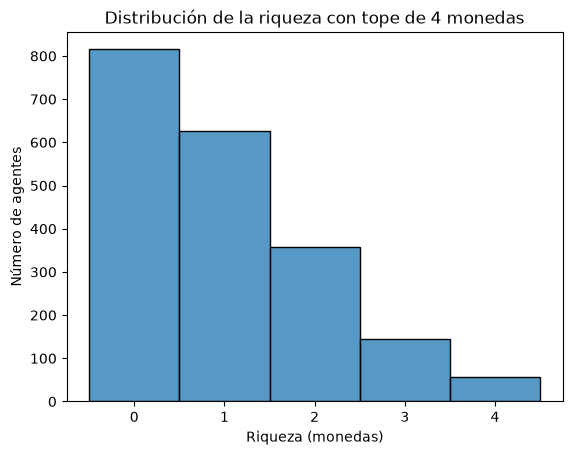

In [618]:
all_wealth: list[int] = []
for rep in range(100):                  # 100 repeticiones del experimento
    model = MoneyModel(20, rng=rep)     # 20 agentes
    for _ in range(20):                 # 20 pasos por repetición
        model.step()
    all_wealth += [agent.wealth for agent in model.agents]

g = sns.histplot(all_wealth, discrete=True, binrange=(0, MAX_WEALTH))
g.set_xticks(range(MAX_WEALTH + 1))
g.set(title="Distribución de la riqueza con tope de 4 monedas",
      xlabel="Riqueza (monedas)", ylabel="Número de agentes");

**Lectura del resultado.** Aunque el tope de cuatro monedas parece una restricción
fuerte, no cambia la estructura de la distribución: Sobre los 2.000 registros (100 réplicas
por 20 agentes) hay 815 agentes en cero y sólo 56 que alcanzaron el tope, de forma que se
mantiene el comportamiento de muchos con poca riqueza y pocos con riqueza alta que se pedía
observar.

Por qué el intercambio sigue siendo aleatorio y sin memoria: Quien entrega
una moneda no tiene garantía de recuperarla, y las monedas terminan acumulándose por puro
azar en unos cuantos bolsillos, con lo cual el tope sólo recorta la cola derecha de la
distribución (nadie supera las cuatro monedas) sin alterar el sesgo hacia la pobreza
mayoritaria.

## Punto 2 — Una dinámica nueva: generosos y tacaños

> Proponga e implemente una modificación adicional al código para simular una nueva
> dinámica. Explique e ilustre sus resultados con gráficas.

**Modificación propuesta.** Se dota a cada agente de un rasgo social que se sortea al nacer
con igual probabilidad: ser generoso o tacaño. La regla actúa sobre el destino de la moneda:
un generoso le entrega a cualquiera, mientras que un tacaño sólo le entrega a otro tacaño
(si el elegido resulta generoso, la transferencia no se realiza y el tacaño conserva su
moneda). Se retira además el tope del punto 1, con el objetivo de que la única diferencia
frente al código de la clase sea la regla social, de modo que cualquier cambio en la
distribución quede atribuible a ella.

In [619]:
class GenerousAgent(MoneyAgent):
    """Agente que nace generoso o tacaño con igual probabilidad."""

    def __init__(self, model: Model):
        super().__init__(model)
        self.is_generous = self.random.random() < 0.5

    def exchange(self):
        if WEALTH_UNIT > self.wealth:
            return

        other_agent: GenerousAgent = self.random.choice(self.model.agents)
        # Regla social: un tacaño no le entrega a un generoso.
        if not self.is_generous and other_agent.is_generous:
            return

        other_agent.wealth += WEALTH_UNIT
        self.wealth -= WEALTH_UNIT


class GenerousModel(MoneyModel):
    """El mismo andamiaje, poblado con agentes generosos y tacaños."""

    agent_cls = GenerousAgent

Riqueza media [ generosos: 0.00 | tacaños: 2.03 ]


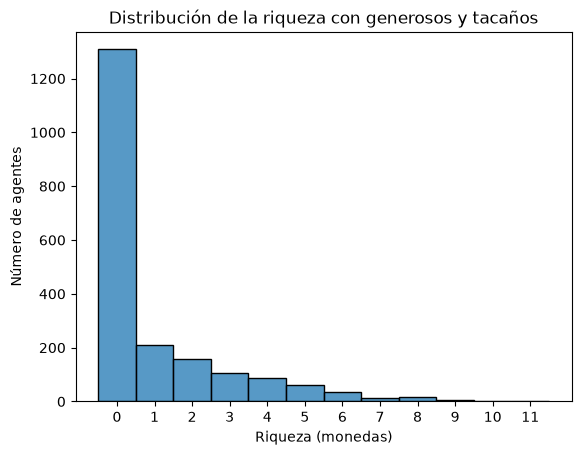

In [620]:
all_wealth: list[int] = []
por_tipo: dict[str, list[int]] = {"generoso": [], "tacaño": []}
for rep in range(100):
    model = GenerousModel(20, rng=rep)
    for _ in range(20):
        model.step()
    for agent in model.agents:
        all_wealth.append(agent.wealth)
        por_tipo["generoso" if agent.is_generous else "tacaño"].append(agent.wealth)

print(f"Riqueza media [ generosos: {np.mean(por_tipo['generoso']):.2f} | "
      f"tacaños: {np.mean(por_tipo['tacaño']):.2f} ]")

g = sns.histplot(all_wealth, discrete=True)
g.set_xticks(range(0, max(all_wealth) + 1))
g.set(title="Distribución de la riqueza con generosos y tacaños",
      xlabel="Riqueza (monedas)", ylabel="Número de agentes");

**Lo que se observa.** La regla social rompe la simetría entre tipos y el efecto es contundente: La riqueza media final es de 0.00 monedas para los generosos y de 2.03 para los tacaños, es decir, toda la riqueza del sistema termina en manos de los tacaños.

La explicación es un puro balance de flujos: El generoso entrega siempre que tiene monedas y sólo recibe de otros generosos, mientras que el tacaño recibe de cualquiera pero falla la mitad de sus intentos de entrega (los que caen en un generoso) conservando la moneda; como los generosos se van vaciando y pronto no queda nadie de su tipo con qué entregar, el flujo hacia ellos se seca y quedan definitivamente en cero.

El histograma lo refleja en la barra gigante del cero junto con una cola derecha larga (hubo agentes con hasta once monedas) que el tope del punto 1 prohibía.

## Punto 3 — Propagación de un chisme

> Modifique el código del Modelo Basado en Agentes que trabajamos en clase para describir
> la dinámica de la propagación de un chisme. El valor 1 en wealth significa que el agente
> conoce el chisme, mientras que el valor 0 indica que no lo conoce. Haga que, de manera
> aleatoria, sólo el 10% de los agentes conozcan inicialmente el chisme. Explique la
> implementación de esta condición inicial. Modifique también la interacción del agente de
> tal forma que se exija que wealth sea 1 para buscar otro agente, e imponga que el agente
> encontrado quede con wealth = 1. Realice un experimento con 20 agentes dando 12 pasos.
> Registre cuántos agentes conocen el chisme en cada paso y grafique el resultado.
> Recuerde que por la naturaleza estocástica de la simulación no tendrá exactamente el
> mismo resultado en cada ejecución.

**Implementación.** El atributo `wealth` del modelo de la clase se reinterpreta como `knows` (diré que True equivale al 1 del enunciado, False a 0) y la condición inicial se implementa como una Bernoulli por agente dentro del constructor: El `self.random.random() < FRACTION_KNOWS` deja `knows=True` sólo en el 10% esperado de la población.

Dos detalles valen la pena mencionar: El sorteo usa el generador aleatorio del modelo (el mismo que alimenta `shuffle_do`), de forma que la condición inicial y la dinámica provienen de una única fuente de aleatoriedad, y al ser un sorteo independiente por agente el número inicial de conocedores no es una cuota fija sino una fluctuación alrededor de 2 agentes (en las 100 réplicas sembradas hubo mínimos de 0 y máximos de 5).

La interacción respeta literalmente el enunciado: Sólo un agente con `knows=True` busca a otro, y el agente encontrado queda con `knows=True`.

In [621]:
FRACTION_KNOWS = 0.1


class GossipAgent(MoneyAgent):
    """Reinterpretación del agente de la clase: knows=True conoce el chiste."""

    def __init__(self, model: Model):
        super().__init__(model)
        # Condición inicial: cada agente conoce el chiste con probabilidad 0.1.
        self.knows: bool = self.random.random() < FRACTION_KNOWS

    def exchange(self):
        # Sólo quien conoce el chiste busca a otro agente y se lo cuenta.
        if not self.knows:
            return

        other_agent: GossipAgent = self.random.choice(self.model.agents)
        other_agent.knows = True


class GossipModel(MoneyModel):
    """El mismo andamiaje, reinterpretado como propagación de un chiste."""

    agent_cls = GossipAgent

Conocedores iniciales: 2.05 de 20 en promedio (mínimo 0, máximo 5)


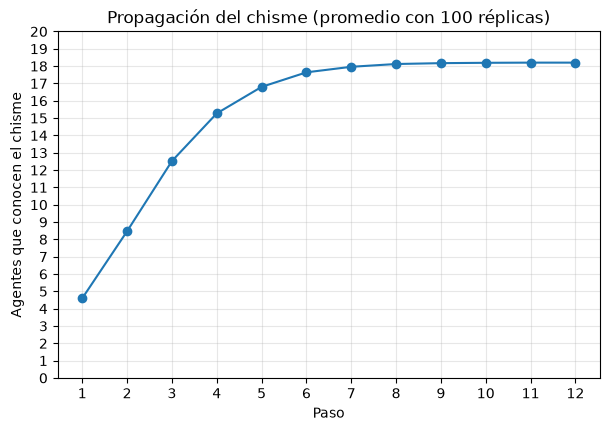

In [622]:
TOTAL_STEPS, N_AGENTS, N_REPS = 12, 20, 100
conocen_por_paso = np.zeros(TOTAL_STEPS)
conocen_inicial = np.zeros(N_REPS)

for rep in range(N_REPS):
    model = GossipModel(N_AGENTS, rng=rep)
    conocen_inicial[rep] = sum(agent.knows for agent in model.agents)
    for paso in range(TOTAL_STEPS):
        model.step()
        conocen_por_paso[paso] += sum(agent.knows for agent in model.agents)

conocen_por_paso /= N_REPS
print(f"Conocedores iniciales: {conocen_inicial.mean():.2f} de {N_AGENTS} en promedio "
      f"(mínimo {conocen_inicial.min():.0f}, máximo {conocen_inicial.max():.0f})")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, TOTAL_STEPS + 1), conocen_por_paso, marker="o")
ax.set_xticks(range(1, TOTAL_STEPS + 1))
ax.set_yticks(range(0, N_AGENTS + 1))
ax.set(title="Propagación del chisme (promedio con 100 réplicas)",
       xlabel="Paso", ylabel="Agentes que conocen el chisme")
ax.grid(alpha=0.3);

**Lectura del resultado.** La curva promedio tiene la forma en S (logística) típica
de los procesos de contagio: Al principio casi nadie conoce el chisme y el crecimiento es
lento (de 2.05 conocedores iniciales a 4.6 al cerrar el primer paso), en la zona media cada
conocedor encuentra con facilidad a alguien que aún no lo sabe y el crecimiento es máximo
(de 4.6 a 15.3 entre los pasos 1 y 4), y hacia el final casi no quedan ignorantes por
contagiar y la curva se aplana.

La meseta queda en torno a 18 de los 20 agentes y no en los
20 exactos, con el pequeño detalle de que alguna réplica arrancó sin conocedores (el sorteo
inicial dio cero, ver el mínimo impreso arriba) y en ella el chisme nunca despega, de modo
que su promedio se arrastra hacia abajo; se grafica el promedio de 100 réplicas precisamente
por la nota final del enunciado, ya que una ejecución individual es estocástica y brincaría
de paso a paso.

Muchas gracias por leer!


Over Haider C. V.

Ingeniero en sistemas y computación.